# Sections 1 and 2: Positioning and Direct Replication

ECON 5200 Midterm Project · Replication Study

> **🛑 AI policy, and it is not the problem sets' policy.** Sections 1 and 2 — the
> positioning and the direct replication — are **no AI**. Not for the code, not for
> the prose. Making a computer agree with a published table is the exercise that
> establishes you can read a paper, and a model that has already read the paper will
> simply hand you the answer without your ever finding the discrepancy. Sections 3 to
> 6 authorise AI as a documented co-pilot under **P.R.I.M.E.**, on the same terms as
> every problem set: you file the full transcript in `ai-appendix.md`, and if you
> cannot explain a line you cannot submit it. State in your README which sections you
> used it in. This follows the course rule — manual command first, expansion second —
> and using AI in Sections 1 or 2 is an integrity violation, not a style disagreement.

## Setup

Imports and paths only.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

# The repository root, whether this runs from notebooks/ (Jupyter) or from the root (reproduce.py).
ROOT = Path.cwd() if (Path.cwd() / "download_data.py").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
(ROOT / "output").mkdir(exist_ok=True)

from download_data import MY_PAPER, PAPERS, fetch

## Data

In [2]:
# Set MY_PAPER once, in download_data.py. fetch() downloads into data/ only if a file is missing.
if MY_PAPER:
    paths = fetch(MY_PAPER)
    print(PAPERS[MY_PAPER]["paper"])
    # TODO: read the file(s), e.g. df = pd.read_stata(paths[0])
else:
    print("TODO: set MY_PAPER in download_data.py (castle, card, lee, dw, hansen or abortion).")

  data/lmb-data.dta  7.2 MB
Lee (2008), incumbency advantage in US House elections


In [ ]:
import pandas as pd

df = pd.read_stata("/workspaces/econ5200-midterm-replication/data/lmb-data.dta")

print(df.shape)
print(df.columns.tolist())
df.head()

(13588, 178)
['state', 'district', 'incmbncy', 'demvote', 'repvote', 'year', 'congress', 'occupanc', 'name', 'eq_Dwhip', 'eq_Rwhip', 'eq_Dlead', 'eq_Rlead', 'vote', 'republic', 'party', 'office', 'icpsr_id', 'whip_D', 'whip_R', 'vote_tot', 'demvoteshare', 'dembin', 'lagdemvoteshare', 'clusterid', 'pooleyear', 'redistrict', 'poolename', 'aclu_vs', 'acu_vs', 'aca_vs', 'ada_vs', 'afbf_vs', 'afge_vs', 'afscme_vs', 'aft_vs', 'asc_vs', 'bfw_vs', 'bctd_vs', 'carter_vs', 'ccus1_vs', 'ccus2_vs', 'cwla_vs', 'cv_vs', 'cvvf_vs', 'sane_vs', 'cfnfmp_vs', 'aflcio_vs', 'cfsca_vs', 'cfsce_vs', 'cfscd_vs', 'cfscs_vs', 'ccause_vs', 'cw_vs', 'cc_vs', 'cfa_vs', 'ike_vs', 'pfpike_vs', 'pdpike_vs', 'ford_vs', 'fcnl_vs', 'lbj_vs', 'pfplbj_vs', 'pdplbj_vs', 'jfk_vs', 'pfpjfk_vs', 'pdpjfk_vs', 'lfr_vs', 'lcv_vs', 'lwv_vs', 'll_vs', 'lfs_vs', 'nasc_vs', 'ncsc_vs', 'nea_vs', 'nfo_vs', 'nfu_vs', 'nfib_vs', 'ntu_vs', 'nwpc_vs', 'nr_vs', 'nixon_vs', 'reagan_vs', 'ripon_vs', 'twr_vs', 'uaw_vs', 'umw_vs', 'firstyear',

,state,district,incmbncy,demvote,repvote,year,congress,occupanc,name,eq_Dwhip,...,pres_rep_pct,n,lagged,_merge,democrat,lagdemocrat,score,lagscore,id,id2
0,01: Connecticut,1,-1: REPUBLICAN,127802.0,103294.0,1948.0,81.0,0.0,"RIBICOFF,",0.752336,...,NaN,1.0,14.760000,3,1.0,0.0,64.339996,14.760000,3.0,1.0
1,01: Connecticut,1,-1: REPUBLICAN,127802.0,103294.0,1948.0,81.0,0.0,"RIBICOFF,",0.752336,...,NaN,2.0,9.520000,3,1.0,0.0,60.279999,9.520000,4.0,1.0
2,01: Connecticut,1,1: DEMOCRAT,134258.0,96251.0,1950.0,82.0,0.0,"RIBICOFF,",0.770270,...,NaN,1.0,64.339996,3,1.0,1.0,57.060001,64.339996,5.0,1.0
3,01: Connecticut,1,1: DEMOCRAT,134258.0,96251.0,1950.0,82.0,0.0,"RIBICOFF,",0.770270,...,NaN,2.0,60.279999,3,1.0,1.0,73.830002,60.279999,6.0,1.0
4,01: Connecticut,1,1: DEMOCRAT,148935.0,112526.0,1954.0,84.0,0.0,DODD,0.730769,...,NaN,1.0,56.220001,3,1.0,1.0,42.959999,56.220001,7.0,1.0


In [5]:
keywords = ["vote", "margin", "share", "win", "dem", "rep"]

for col in df.columns:
    if any(word in col.lower() for word in keywords):
        print(col)

demvote
repvote
vote
republic
vote_tot
demvoteshare
dembin
lagdemvoteshare
demvs2
demvs3
demvs4
lagdemvs2
lagdemvs3
lagdemvs4
dem2
lagdem2
pres_dem_pct
pres_rep_pct
democrat
lagdemocrat


In [6]:
cols = [
    "year",
    "demvoteshare",
    "lagdemvoteshare",
    "dembin",
    "democrat",
    "lagdemocrat"
]

print(df[cols].describe().round(3))
print(df[cols].head(10))

            year  demvoteshare  lagdemvoteshare     dembin   democrat  \
count  13588.000     13577.000        13577.000  13577.000  13588.000   
mean    1969.459         0.582            0.577      0.578      0.597   
std       12.754         0.230            0.226      0.230      0.491   
min     1948.000         0.000            0.000      0.000      0.000   
25%     1958.000         0.416            0.411      0.410      0.000   
50%     1970.000         0.557            0.546      0.550      1.000   
75%     1980.000         0.720            0.712      0.710      1.000   
max     1990.000         1.000            1.000      1.000      1.000   

       lagdemocrat  
count    13588.000  
mean         0.583  
std          0.493  
min          0.000  
25%          0.000  
50%          1.000  
75%          1.000  
max          1.000  
     year  demvoteshare  lagdemvoteshare  dembin  democrat  lagdemocrat
0  1948.0      0.553026         0.469256    0.55       1.0          0.0
1  1948.0

In [7]:
cols = [
    "state",
    "district",
    "year",
    "demvoteshare",
    "lagdemvoteshare",
    "democrat",
    "lagdemocrat"
]

print(df[cols].head(15).to_string(index=False))

          state  district   year  demvoteshare  lagdemvoteshare  democrat  lagdemocrat
01: Connecticut         1 1948.0      0.553026         0.469256       1.0          0.0
01: Connecticut         1 1948.0      0.553026         0.469256       1.0          0.0
01: Connecticut         1 1950.0      0.582441         0.553026       1.0          1.0
01: Connecticut         1 1950.0      0.582441         0.553026       1.0          1.0
01: Connecticut         1 1954.0      0.569626         0.539680       1.0          1.0
01: Connecticut         1 1954.0      0.569626         0.539680       1.0          1.0
01: Connecticut         1 1956.0      0.463041         0.569626       0.0          1.0
01: Connecticut         1 1956.0      0.463041         0.569626       0.0          1.0
01: Connecticut         1 1958.0      0.543411         0.463041       1.0          0.0
01: Connecticut         1 1958.0      0.543411         0.463041       1.0          0.0
01: Connecticut         1 1960.0      0.584

In [39]:
import pandas as pd

# Load the dataset
df = pd.read_stata("/workspaces/econ5200-midterm-replication/data/lmb-data.dta")

# Check variable labels
reader = pd.io.stata.StataReader("/workspaces/econ5200-midterm-replication/data/lmb-data.dta")
labels = reader.variable_labels()

variables = [
    "demvoteshare",
    "lagdemvoteshare",
    "democrat",
    "lagdemocrat",
    "dembin"
]

print("Variable labels:")
for name in variables:
    print(name, ":", labels.get(name, "No label"))

# Check duplicate observations
print("\nData checks:")
print("Total rows:", len(df))
print("Total columns:", len(df.columns))
print("Exact duplicate rows:", df.duplicated().sum())

print(
    "Repeated state-district-year combinations:",
    df.duplicated(subset=["state", "district", "year"]).sum()
)

Variable labels:
demvoteshare : 
lagdemvoteshare : 
democrat : 
lagdemocrat : 
dembin : 

Data checks:
Total rows: 13588
Total columns: 178
Exact duplicate rows: 0
Repeated state-district-year combinations: 6446


In [10]:
# Compare two records from the same district and year

subset = df[
    (df["state"].astype(str).str.contains("Connecticut")) &
    (df["district"] == 1) &
    (df["year"] == 1948)
]

print("Number of records:", len(subset))

if len(subset) >= 2:
    row1 = subset.iloc[0]
    row2 = subset.iloc[1]

    differences = pd.DataFrame({
        "Record 1": row1,
        "Record 2": row2
    })

    differences = differences[
        differences["Record 1"].astype(str) !=
        differences["Record 2"].astype(str)
    ]

    print(differences.to_string())

Number of records: 2
               Record 1   Record 2
pooleyear        1949.0     1950.0
aclu_vs             NaN        NaN
acu_vs              NaN        NaN
aca_vs              NaN        NaN
ada_vs              NaN        NaN
afbf_vs             NaN        NaN
afge_vs             NaN        NaN
afscme_vs           NaN        NaN
aft_vs              NaN        NaN
asc_vs              NaN        NaN
bfw_vs              NaN        NaN
bctd_vs             NaN        NaN
carter_vs           NaN        NaN
ccus1_vs            NaN        NaN
ccus2_vs            NaN        NaN
cwla_vs             NaN        NaN
cv_vs               NaN        NaN
cvvf_vs             NaN        NaN
sane_vs             NaN        NaN
cfnfmp_vs           NaN        NaN
aflcio_vs           NaN        NaN
cfsca_vs            NaN        NaN
cfsce_vs            NaN        NaN
cfscd_vs            NaN        NaN
cfscs_vs            NaN        NaN
ccause_vs           NaN        NaN
cw_vs               NaN        NaN

In [11]:
import pandas as pd

subset = df[
    (df["state"].astype(str).str.contains("Connecticut")) &
    (df["district"] == 1) &
    (df["year"] == 1948)
]

a = subset.iloc[0]
b = subset.iloc[1]

# Treat two missing values as equal
different = ~(a.eq(b) | (a.isna() & b.isna()))

comparison = pd.DataFrame({
    "Record 1": a[different],
    "Record 2": b[different]
})

print("Actual differences:", different.sum())
print(comparison.to_string())

Actual differences: 11
            Record 1   Record 2
pooleyear     1949.0     1950.0
adayear         1949       1950
nomada            84         73
realada    64.339996  60.279999
lagnomada       25.0       30.0
avgada          53.0       74.5
n                1.0        2.0
lagged         14.76       9.52
score      64.339996  60.279999
lagscore       14.76       9.52
id               3.0        4.0


## Section 1: Positioning (12 pts)

Two pages maximum in the report. What question the paper asks, what was believed before it, what it changed, and how it has been received, with at least three citations to work that engages with it critically. Then the identification strategy and the assumption it rests on, in your own words.

The prose goes in the report. Keep your notes and the three citations here.

**Critical citations (at least three):**

1. Caughey & Sekhon (2011)：Questioning whether the candidates who narrowly won or narrowly lost are truly comparable.
2. Eggers et al. (2015)：Examine whether there is sorting around the cutoff in close elections.
3. de la Cuesta & Imai (2016): Discuss the identification assumptions and common misunderstandings of RDD.

**The identification strategy and its assumption, in my own words:**

Lee (2008) uses a regression discontinuity design (RDD) with a 50% vote share cutoff. The study compares parties that barely win an election with those that barely lose. Since these elections are very close, the two groups are likely to be similar. The main assumption is that election results cannot be precisely manipulated around the cutoff and other relevant factors change smoothly. This helps estimate how winning an election affects the party's vote share in the next election.

## Section 2: Direct Replication (24 pts)

Reproduce the paper's headline result and report your number beside theirs. You will not match exactly. Document every discrepancy and its likely source: sample construction, variable definition, software defaults, a decision the paper does not describe. Where the paper is ambiguous about a choice, say so: those ambiguities are your Section 3.

In [12]:
# Check observations near the 50% cutoff

rd_check = df[
    ["lagdemvoteshare", "lagdemocrat", "demvoteshare"]
].dropna().copy()

rd_check["margin"] = rd_check["lagdemvoteshare"] - 0.5

near_cutoff = rd_check[
    rd_check["margin"].abs() <= 0.05
]

print("Total usable observations:", len(rd_check))
print("Observations within 5 percentage points:", len(near_cutoff))

print("\nPrevious election winners:")
print(near_cutoff["lagdemocrat"].value_counts())

print("\nSample observations:")
print(near_cutoff.head())

Total usable observations: 13566
Observations within 5 percentage points: 2441

Previous election winners:
lagdemocrat
1.0    1226
0.0    1215
Name: count, dtype: int64

Sample observations:
   lagdemvoteshare  lagdemocrat  demvoteshare    margin
0         0.469256          0.0      0.553026 -0.030744
1         0.469256          0.0      0.553026 -0.030744
4         0.539680          1.0      0.569626  0.039680
5         0.539680          1.0      0.569626  0.039680
8         0.463041          0.0      0.543411 -0.036959


In [13]:
# Check treatment assignment around the cutoff

check = rd_check.copy()

check["win_from_share"] = (
    check["lagdemvoteshare"] >= 0.5
).astype(int)

mismatch = check[
    check["win_from_share"] != check["lagdemocrat"]
]

print("Total observations:", len(check))
print("Treatment mismatches:", len(mismatch))

print(
    mismatch[
        ["lagdemvoteshare", "lagdemocrat", "win_from_share"]
    ].head(10)
)

Total observations: 13566
Treatment mismatches: 0
Empty DataFrame
Columns: [lagdemvoteshare, lagdemocrat, win_from_share]
Index: []


In [14]:
import statsmodels.formula.api as smf

# Use observations close to the cutoff
bandwidth = 0.05

rd_sample = rd_check[
    rd_check["margin"].abs() <= bandwidth
].copy()

# Allow different slopes on each side
rd_sample["interaction"] = (
    rd_sample["margin"] * rd_sample["lagdemocrat"]
)

# Local linear RDD regression
model = smf.ols(
    "demvoteshare ~ lagdemocrat + margin + interaction",
    data=rd_sample
).fit(cov_type="HC1")

print("Bandwidth:", bandwidth)
print("Sample size:", len(rd_sample))
print("RDD estimate:", round(model.params["lagdemocrat"], 4))
print("Standard error:", round(model.bse["lagdemocrat"], 4))
print("P-value:", round(model.pvalues["lagdemocrat"], 4))

print(model.summary())


Bandwidth: 0.05
Sample size: 2441
RDD estimate: 0.0906
Standard error: 0.0076
P-value: 0.0
                            OLS Regression Results                            
Dep. Variable:           demvoteshare   R-squared:                       0.321
Model:                            OLS   Adj. R-squared:                  0.321
Method:                 Least Squares   F-statistic:                     374.2
Date:                Tue, 10 Nov 2026   Prob (F-statistic):          6.92e-200
Time:                        03:23:26   Log-Likelihood:                 2178.2
No. Observations:                2441   AIC:                            -4348.
Df Residuals:                    2437   BIC:                            -4325.
Df Model:                           3                                         
Covariance Type:                  HC1                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------

In [15]:

# Save the preliminary RDD result
rdd_estimate = model.params["lagdemocrat"]
rdd_se = model.bse["lagdemocrat"]
rdd_pvalue = model.pvalues["lagdemocrat"]
rdd_n = int(model.nobs)

print("RDD estimate:", round(rdd_estimate, 4))
print("Standard error:", round(rdd_se, 4))
print("P-value:", rdd_pvalue)
print("Sample size:", rdd_n)


RDD estimate: 0.0906
Standard error: 0.0076
P-value: 7.760979933121489e-33
Sample size: 2441


In [16]:
# Check RDD estimates with different bandwidths

import statsmodels.formula.api as smf

for bw in [0.03, 0.05, 0.07, 0.10]:
    sample = rd_check[
        rd_check["margin"].abs() <= bw
    ].copy()

    sample["interaction"] = (
        sample["margin"] * sample["lagdemocrat"]
    )

    result = smf.ols(
        "demvoteshare ~ lagdemocrat + margin + interaction",
        data=sample
    ).fit(cov_type="HC1")

    print(
        f"Bandwidth: {bw:.2f}, "
        f"N: {len(sample)}, "
        f"Estimate: {result.params['lagdemocrat']:.4f}, "
        f"SE: {result.bse['lagdemocrat']:.4f}"
    )


Bandwidth: 0.03, N: 1459, Estimate: 0.0914, SE: 0.0099
Bandwidth: 0.05, N: 2441, Estimate: 0.0906, SE: 0.0076
Bandwidth: 0.07, N: 3442, Estimate: 0.0915, SE: 0.0065
Bandwidth: 0.10, N: 4783, Estimate: 0.0980, SE: 0.0056


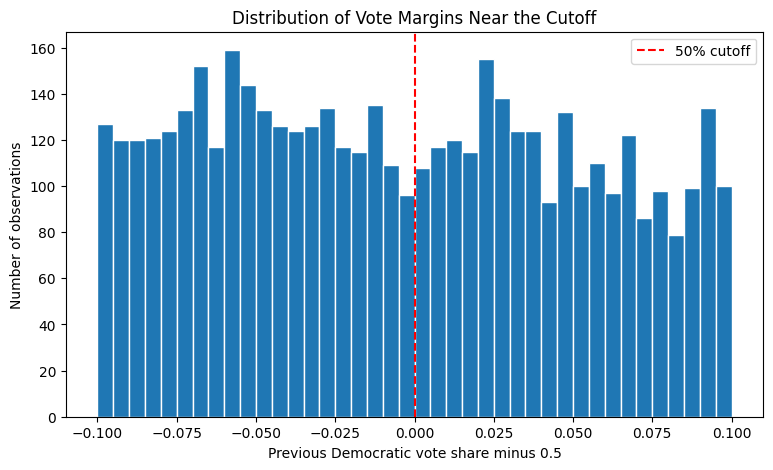

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

x = rd_check["margin"].dropna()

bins = np.arange(-0.10, 0.105, 0.005)

plt.figure(figsize=(9, 5))

plt.hist(x, bins=bins, edgecolor="white")
plt.axvline(0, color="red", linestyle="--",
            label="50% cutoff")

plt.xlabel("Previous Democratic vote share minus 0.5")
plt.ylabel("Number of observations")
plt.title("Distribution of Vote Margins Near the Cutoff")
plt.legend()
plt.savefig("output/vote_margin_histogram.png", dpi=300, bbox_inches="tight")
plt.show()


In [20]:
%pip install rddensity

/workspaces/econ5200-midterm-replication/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.


In [22]:
import sys

print("Python path:", sys.executable)

%pip show rddensity

Python path: /workspaces/econ5200-midterm-replication/.venv/bin/python
/workspaces/econ5200-midterm-replication/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.


In [24]:
import sys
import subprocess

result = subprocess.run(
    [sys.executable, "-m", "ensurepip", "--upgrade"],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print("Error details:")
print(result.stderr)

Return code: 1
Error details:
/workspaces/econ5200-midterm-replication/.venv/bin/python: No module named ensurepip



In [27]:
import subprocess
import sys

subprocess.run([
    "/home/codespace/.python/current/bin/pip",
    "--python", sys.executable,
    "install",
    "rddensity"
], check=True)

  Using cached rddensity-3.0-py3-none-any.whl.metadata (4.5 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached plotnine-0.15.9-py3-none-any.whl.metadata (9.7 kB)
  Using cached lpdensity-3.0.0-py3-none-any.whl.metadata (4.0 kB)
  Using cached mizani-0.14.6-py3-none-any.whl.metadata (4.8 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
Using cached rddensity-3.0-py3-none-any.whl (20 kB)
Using cached lpdensity-3.0.0-py3-none-any.whl (18 kB)
Using cached plotnine-0.15.9-py3-none-any.whl (1.6 MB)
Using cached mizani-0.14.6-py3-none-any.whl (134 kB)
Using cached sympy-1.14.0-py3-none-any.whl (6.3 MB)
Using cached mpmath-1.3.0-py3-none-any.whl (536 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [rddensity]/6 [plotnine]


CompletedProcess(args=['/home/codespace/.python/current/bin/pip', '--python', '/workspaces/econ5200-midterm-replication/.venv/bin/python', 'install', 'rddensity'], returncode=0)

In [28]:
from rddensity import rddensity

density_result = rddensity(
    X=rd_check["margin"].dropna().to_numpy(),
    c=0
)

print(density_result)

Call: rddensity

Sample Size:                                       13566
Cutoff:                                                0
Model:                                      unrestricted
Kernel:                                       triangular
VCE:                                           jackknife



In [29]:
print(density_result)
print(density_result.test)

Call: rddensity

Sample Size:                                       13566
Cutoff:                                                0
Model:                                      unrestricted
Kernel:                                       triangular
VCE:                                           jackknife

t_asy         NaN
t_jk     0.603218
p_asy         NaN
p_jk     0.546363
dtype: float64


In [ ]:

import pandas as pd

density_table = pd.DataFrame({
    "test": ["Density test (jackknife)"],
    "sample_size": [13566],
    "cutoff": [0],
    "test_statistic": [density_result.test["t_jk"]],
    "p_value": [density_result.test["p_jk"]]
})

density_table.to_csv(
    "output/density_test.csv",
    index=False
)

print(density_table)


                       test  sample_size  cutoff  test_statistic   p_value
0  Density test (jackknife)        13566       0        0.603218  0.546363


### Theirs vs mine

One row per number you replicate. The row label says where the number is in the paper (for example, `Table 2, col 3: effect on log wage`). `gap_pct` is computed for you as 100 × (mine − theirs) / |theirs|. This cell writes `output/headline_table.csv`, which `python reproduce.py` prints and your README quotes.

In [47]:
import pandas as pd
from pathlib import Path

ROOT = Path("/workspaces/econ5200-midterm-replication")

paper_estimate = 0.077
my_estimate = clean_model.params["lagdemocrat"]
headline = pd.DataFrame({
    "paper_estimate": [paper_estimate],
    "my_estimate": [my_estimate],
    "likely_source": [
        "Sample selection and standard error method"
    ]
}, index=["Table 2, col 1: vote share t+1"])

headline.index.name = "estimate"

headline["gap_pct"] = (
    100 * (headline["my_estimate"] -
           headline["paper_estimate"])
    / abs(paper_estimate)
)

headline = headline[
    ["paper_estimate", "my_estimate",
     "gap_pct", "likely_source"]
]
(ROOT / "output").mkdir(parents=True, exist_ok=True)
headline.to_csv(ROOT / "output" / "headline_table.csv")

print(headline.round(4))

                                paper_estimate  my_estimate  gap_pct  \
estimate                                                               
Table 2, col 1: vote share t+1           0.077       0.0815   5.8287   

                                                             likely_source  
estimate                                                                    
Table 2, col 1: vote share t+1  Sample selection and standard error method  


In [41]:
[col for col in df.columns
 if "margin" in col.lower()
 or "vote" in col.lower()
 or "dem" in col.lower()]

['demvote',
 'repvote',
 'vote',
 'vote_tot',
 'demvoteshare',
 'dembin',
 'lagdemvoteshare',
 'demvs2',
 'demvs3',
 'demvs4',
 'lagdemvs2',
 'lagdemvs3',
 'lagdemvs4',
 'dem2',
 'lagdem2',
 'pres_dem_pct',
 'democrat',
 'lagdemocrat']

In [42]:
cols = [
    "demvoteshare",
    "lagdemvoteshare",
    "demvs2",
    "lagdemvs2",
    "lagdemocrat"
]

print(df[cols].describe().round(4))
print("\nFirst 10 observations:")
print(df[cols].head(10))

       demvoteshare  lagdemvoteshare      demvs2   lagdemvs2  lagdemocrat
count    13577.0000       13577.0000  13577.0000  13577.0000   13588.0000
mean         0.5819           0.5768      0.3913      0.3840       0.5827
std          0.2295           0.2264      0.2875      0.2853       0.4931
min          0.0000           0.0000      0.0000      0.0000       0.0000
25%          0.4156           0.4107      0.1727      0.1687       0.0000
50%          0.5571           0.5463      0.3103      0.2984       1.0000
75%          0.7196           0.7118      0.5178      0.5067       1.0000
max          1.0000           1.0000      1.0000      1.0000       1.0000

First 10 observations:
   demvoteshare  lagdemvoteshare    demvs2  lagdemvs2  lagdemocrat
0      0.553026         0.469256  0.305837   0.220201          0.0
1      0.553026         0.469256  0.305837   0.220201          0.0
2      0.582441         0.553026  0.339238   0.305837          1.0
3      0.582441         0.553026  0.339238

In [43]:
import pandas as pd
import statsmodels.formula.api as smf

# Keep observations with the needed variables
data = df[[
    "demvoteshare", "lagdemvoteshare",
    "lagdemocrat", "state", "district", "year"
]].dropna().copy()

# Running variable, centered at 50%
data["margin"] = data["lagdemvoteshare"] - 0.5

# Fourth-order polynomial, with separate slopes
# on the two sides of the cutoff
for p in range(1, 5):
    data[f"margin{p}"] = data["margin"] ** p
    data[f"win_margin{p}"] = (
        data["lagdemocrat"] * data[f"margin{p}"]
    )

terms = ["lagdemocrat"]
terms += [f"margin{p}" for p in range(1, 5)]
terms += [f"win_margin{p}" for p in range(1, 5)]

formula = "demvoteshare ~ " + " + ".join(terms)

model = smf.ols(formula, data=data).fit(cov_type="HC1")

print("Paper estimate: 0.077")
print("My estimate:", round(model.params["lagdemocrat"], 4))
print("Standard error:", round(model.bse["lagdemocrat"], 4))
print("Sample size:", int(model.nobs))


Paper estimate: 0.077
My estimate: 0.0861
Standard error: 0.0069
Sample size: 13566


In [44]:
print("Current sample:", len(data))

print("Unique state-district-year:",
      data[["state", "district", "year"]]
      .drop_duplicates().shape[0])

print("\nObservations by year:")
print(data.groupby("year").size())

Current sample: 13566
Unique state-district-year: 7130

Observations by year:
year
1948.0    748
1950.0    743
1954.0    772
1956.0    799
1958.0    792
1960.0    399
1964.0    790
1966.0    828
1968.0    818
1970.0    814
1974.0    811
1976.0    813
1978.0    803
1980.0    800
1984.0    794
1986.0    709
1988.0    631
1990.0    702
dtype: int64


In [45]:
keys = ["state", "district", "year"]

counts = data.groupby(keys).size()

print("Groups with 1 row:", (counts == 1).sum())
print("Groups with 2 rows:", (counts == 2).sum())
print("Groups with more than 2 rows:", (counts > 2).sum())

print("\nSample duplicate records:")
print(
    df[df.duplicated(keys, keep=False)]
    [keys + ["demvoteshare", "lagdemvoteshare", "lagdemocrat"]]
    .head(10)
)

Groups with 1 row: 694
Groups with 2 rows: 6436
Groups with more than 2 rows: 0

Sample duplicate records:
             state  district    year  demvoteshare  lagdemvoteshare  \
0  01: Connecticut         1  1948.0      0.553026         0.469256   
1  01: Connecticut         1  1948.0      0.553026         0.469256   
2  01: Connecticut         1  1950.0      0.582441         0.553026   
3  01: Connecticut         1  1950.0      0.582441         0.553026   
4  01: Connecticut         1  1954.0      0.569626         0.539680   
5  01: Connecticut         1  1954.0      0.569626         0.539680   
6  01: Connecticut         1  1956.0      0.463041         0.569626   
7  01: Connecticut         1  1956.0      0.463041         0.569626   
8  01: Connecticut         1  1958.0      0.543411         0.463041   
9  01: Connecticut         1  1958.0      0.543411         0.463041   

   lagdemocrat  
0          0.0  
1          0.0  
2          1.0  
3          1.0  
4          1.0  
5        

In [46]:
# Check whether duplicate elections have different key variables
keys = ["state", "district", "year"]
variables = ["demvoteshare", "lagdemvoteshare", "lagdemocrat"]

differences = (
    data.groupby(keys)[variables]
    .nunique(dropna=False)
    .gt(1)
    .any(axis=1)
)

print("Groups with conflicting election variables:",
      differences.sum())

if differences.sum() == 0:
    clean_data = data.drop_duplicates(subset=keys).copy()

    clean_model = smf.ols(
        formula, data=clean_data
    ).fit(cov_type="HC1")

    print("Paper estimate: 0.077")
    print("My estimate:",
          round(clean_model.params["lagdemocrat"], 4))
    print("Standard error:",
          round(clean_model.bse["lagdemocrat"], 4))
    print("Sample size:", int(clean_model.nobs))
else:
    print("Do not deduplicate yet. Some records differ.")

Groups with conflicting election variables: 0
Paper estimate: 0.077
My estimate: 0.0815
Standard error: 0.0095
Sample size: 7130


### Discrepancy log

One row per discrepancy, including the ones you could not explain. A clean match reported without investigation is less credible than a 3% gap that is explained.

| # | Estimate (row above) | What differs | Size of the gap | Likely source | How I checked it | Is the paper ambiguous here? |
|---|---|---|---|---|---|---|
| 1 | Table 2, col 1 | My estimate is 0.0815, compared with 0.077 in the paper. | 5.83% | Different sample selection and model settings| I checked repeated election records and reran the regression with one row per election.| The exact sample restrictions still need to be checked. |
| 2 | | | | | | |

**Ambiguities in the paper, to take into Section 3:**

- I could not fully match the sample size in the paper. My sample has 7,130 observations, while the paper reports 6,558. I will check how the sample restrictions affect the result.